In [1]:
import sys
import json
from pathlib import Path
sys.path.append('../src/')
#from correlation_analysis import *
#from raw_data_inspection import *
import numpy as np
from matplotlib.colors import LogNorm   
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.colors import LinearSegmentedColormap

from IPython.display import display, Math

nps_custom = LinearSegmentedColormap.from_list(
  'nps_custom', [
    (0.00, '#000000'),
    (0.12, '#342c7a'),
    (0.25, '#a43479'),
    (0.55, '#d74444'),
    (0.78, '#f3de80'),
    (1.00, '#ffffff'),
], N=256
)

# nipy_spectral through the red, stopping before the gray-white tip
_nipy = plt.colormaps['nipy_spectral'](np.linspace(0, 0.94, 256))
nipy_spectral_nowhite = LinearSegmentedColormap.from_list('nipy_spectral_nowhite', _nipy, N=256)



plt.rcParams['font.sans-serif'] = ['Helvetica']

legend_ax_font = 12
ax_label_font = 16
ax_title_font = 18

minor_tick_length = 6
major_tick_length = 9
minor_tick_width = 0.75
major_tick_width = 1.0

fig_size = (8,5)


In [2]:


CONFIG_FILE_NAME = "config_NPS_example.json"
Scan = 219

config_file = Path('../configs/' + CONFIG_FILE_NAME)

with open(config_file, "r") as file:
    config = json.load(file)

### Output Directory ###
figure_path = config_file.parent.parent / config.get("Figures")
figure_path.mkdir(parents=True, exist_ok=True)

BASE_DIR     = Path(config.get("Base"))
dataset_path = Path(config.get(f"{Scan}"))
work_path    = BASE_DIR / dataset_path
results_path = work_path / Path(config.get("Results")) / Path(config.get(f"{Scan}_results"))
processed_path = work_path / Path(config.get("Processed")) / Path(config.get(f"{Scan}_processed"))

print(f"Results file: {results_path}")
print(f"Exists: {results_path.exists()}")


Results file: /Users/eriklamb/data/PETRA/PETRA_P10_November2023/Beamtime_11017686/raw/NPS_01_00219/e4m/results/particle2_temp298.0K_scan219_crop0x0_ms1_nr5ns1_bin1_st0_tb1800_newmaskTrue_tiltTrue.h5
Exists: True


In [3]:
# Open raw .h5 in the run directory; raw images at entry/data/data
import h5py


with h5py.File(processed_path, "r") as f_raw:
    sam2det = f_raw['experimental_parameters/sam_to_det'][0] #mm
    pix = f_raw['experimental_parameters/pixel_size'][0] #mm
    lamb = f_raw['experimental_parameters/wavelength'][0] #Å
    dset = f_raw["data/det/"][:,:,:]


#Example: read first frame as 2D image
frame0 = np.sum(dset[0:20], axis=0)
if frame0.ndim == 2:
    raw_image = frame0
else:
    raw_image = frame0[0]  # in case first dim is segment or similar

In [4]:
roi = [450,950,300,700]
#cropped = raw_image[roi[0]:roi[1],roi[2]:roi[3]]+1**(-5)


roi_size = 25
half = roi_size // 2
n_grid = 7
spacing = roi_size  # center-to-center spacing (pixels); ROIs touch edge-to-edge
h, w = raw_image[roi[0]:roi[1],roi[2]:roi[3]].shape
cy, cx = h // 2, w // 2
offsets = np.arange(n_grid) - (n_grid - 1) // 2  # [-2, -1, 0, 1, 2]
roi_bounds = np.empty((n_grid, n_grid, 4), dtype=int)   # [row0, row1, col0, col1]
roi_slices = np.empty((n_grid, n_grid), dtype=object)   # (slice, slice) per ROI
for ii, dy in enumerate(offsets):
    for jj, dx in enumerate(offsets):
        r0 = cy + int(dy * spacing) - half
        c0 = cx + int(dx * spacing) - half
        r1, c1 = r0 + roi_size, c0 + roi_size
        roi_bounds[ii, jj] = [r0, r1, c0, c1]
        roi_slices[ii, jj] = (slice(r0, r1), slice(c0, c1))
def extract_roi(img, i, j):
    """Return 50×50 patch from grid index (i, j), i/j in 0..4."""
    rs, cs = roi_slices[i, j]
    return img[rs, cs]
# Full image with small offset for log display; center patch at grid[2, 2]
cropped = raw_image[roi[0]:roi[1],roi[2]:roi[3]]
center_roi = extract_roi(raw_image[roi[0]:roi[1],roi[2]:roi[3]], n_grid//2, n_grid//2)


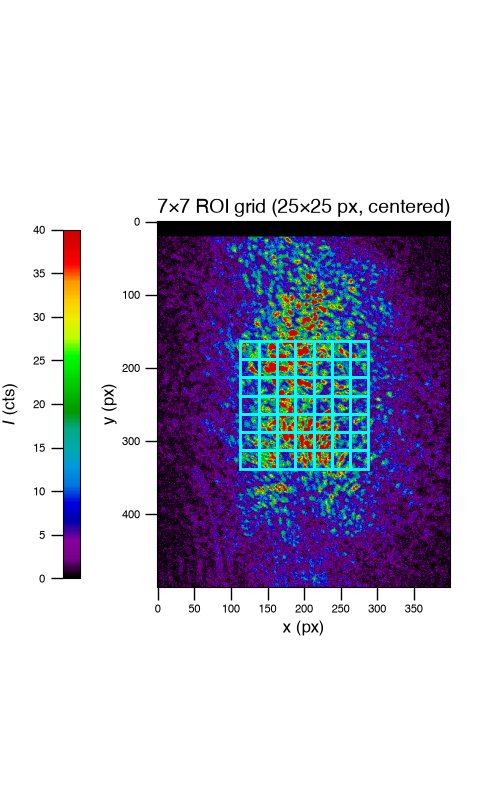

In [5]:
%matplotlib widget


fig, ax = plt.subplots(figsize=(5,8))
im = ax.imshow(cropped, cmap=nipy_spectral_nowhite,vmin=0,vmax=40)
for ii in range(n_grid):
    for jj in range(n_grid):
        r0, r1, c0, c1 = roi_bounds[ii, jj]
        ax.add_patch(
            plt.Rectangle(
                (c0, r0), roi_size, roi_size,
                fill=False, edgecolor="cyan", linewidth=2.0,
            )
        )
ax.set_title(f"{n_grid}×{n_grid} ROI grid ({roi_size}×{roi_size} px, centered)",fontsize=ax_title_font-4  )
ax.set_xlabel("x (px)",fontsize=ax_label_font-4)
ax.set_ylabel("y (px)",fontsize=ax_label_font-4)
ax.tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font-4)
ax.tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=legend_ax_font-4)

# Add a color scale bar for the cropped image on the left side
cbar = plt.colorbar(im, ax=ax, fraction=0.045, pad=0.2, location="left")
cbar.set_label("$I$ (cts)", fontsize=ax_label_font-4, labelpad=10)

cbar.ax.tick_params(labelsize=legend_ax_font-4)
# Make colorbar ticks longer, bolder
cbar.ax.tick_params(labelsize=legend_ax_font-4, length=major_tick_length, width=major_tick_width, which='major', direction='out', color='black')
cbar.ax.tick_params(labelsize=legend_ax_font-4, length=minor_tick_length, width=minor_tick_width, which='minor', direction='out', color='black')

# Move colorbar label to the left for vertical bar
cbar.ax.yaxis.set_label_position('left')

# Add a scale bar: 50 pixels (adjust as needed)
"""""
scalebar_length = 50  # pixels
scalebar_px = scalebar_length
y_loc = cropped.shape[0] - 40  # 40 px from the bottom
x_loc = cropped.shape[1] - scalebar_px - 40  # 40 px from the right
ax.plot(
    [x_loc, x_loc + scalebar_px],
    [y_loc, y_loc],
    color="white", lw=8, solid_capstyle="butt"
)
ax.text(
    x_loc + scalebar_px/2, y_loc - 10,
    f"{scalebar_length} px",
    color="white", fontsize=16, ha="center", va="bottom", weight="bold", backgroundcolor="black", alpha=0.7
)
"""""

plt.show()

fig.savefig(figure_path / "roi_grid.pdf",format="pdf",dpi=300,bbox_inches="tight",metadata={'Creator': ''})


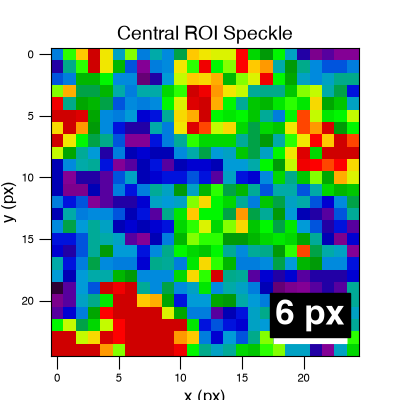

In [6]:
# Example: center ROI of the grid (grid index 2, 2)
speckle = center_roi 
fig,ax = plt.subplots(figsize=(4,4))
ax.imshow(speckle,cmap=nipy_spectral_nowhite,clim=(0,40))
ax.set_title("Central ROI Speckle",fontsize=ax_title_font-4)
ax.set_xlabel("x (px)",fontsize=ax_label_font-4)
ax.set_ylabel("y (px)",fontsize=ax_label_font-4)
ax.tick_params(axis='both', which='major', labelsize=legend_ax_font-4, length=major_tick_length, direction='out')
ax.tick_params(axis='both', which='minor', length=minor_tick_length, direction='out')

scalebar_length = 6  # pixels
scalebar_px = scalebar_length
y_loc = speckle.shape[0] - 2  # 40 px from the bottom
x_loc = speckle.shape[1] - scalebar_px - 1.5  # 40 px from the right
ax.plot(
    [x_loc, x_loc + scalebar_px],
    [y_loc, y_loc],
    color="white", lw=8, solid_capstyle="butt"
)
ax.text(
    x_loc + scalebar_px/2, y_loc - 0.5,
    f"{scalebar_length} px",
    color="white", fontsize=25, ha="center", va="bottom", weight="bold", backgroundcolor="black", alpha=1
)

plt.show()
fig.savefig(figure_path / "central_roi.pdf",format="pdf",dpi=300,bbox_inches="tight",metadata={'Creator': ''})



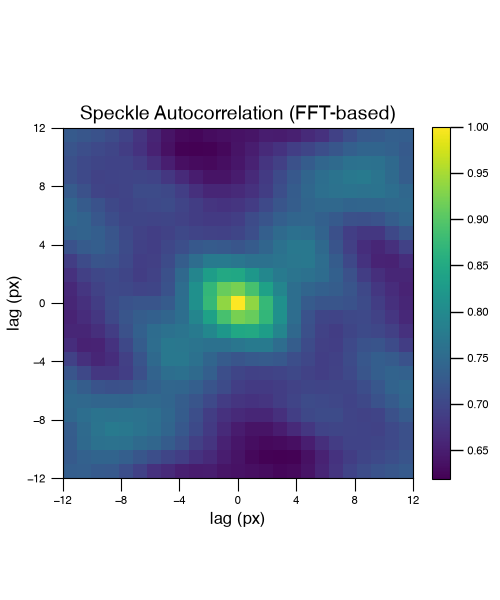

In [7]:
# 2D autocorrelation of speckle image (cross-correlation with itself via FFT)
img = np.asarray(speckle, dtype=float)
F = np.fft.fft2(img)
power = np.abs(F) ** 2
acorr = np.fft.ifft2(power).real
acorr = np.fft.fftshift(acorr)  # center zero lag
acorr = acorr / acorr.max()  # normalize so peak = 1

# Set up axes to range from -12 to 12 pixels
lag_range = 12
ny, nx = acorr.shape
# The side of acorr should be (2*lag_range + 1) for this to make sense exactly
extent = [-lag_range, lag_range, -lag_range, lag_range]
xticks = np.arange(-12, 13, 4)
yticks = np.arange(-12, 13, 4)

fig, ax = plt.subplots(figsize=(5, 6))
im = ax.imshow(acorr, origin="upper", cmap="viridis", extent=extent)
ax.set_title("Speckle Autocorrelation (FFT-based)", fontsize=ax_title_font-4)
ax.set_xlabel("lag (px)", fontsize=ax_label_font-4)
ax.set_ylabel("lag (px)", fontsize=ax_label_font-4)

ax.set_xticks(xticks)
ax.set_yticks(yticks)

ax.tick_params(axis='both', which='major', labelsize=legend_ax_font-4, length=major_tick_length, direction='out')
ax.tick_params(axis='both', which='minor', length=minor_tick_length, direction='out')

# Add a color scale bar for the cropped image on the left side
cbar = plt.colorbar(im, ax=ax, fraction=0.0455, pad=0.05, location="right")
cbar.set_label("Normalized Correlation", fontsize=ax_label_font-4, labelpad=10)
# Make colorbar ticks longer, bolder
cbar.ax.tick_params(labelsize=legend_ax_font-4, length=major_tick_length, width=major_tick_width, which='both', direction='out', color='black')

plt.show()

#fig.savefig(figure_path / "speckle_acorr.pdf", format="pdf", dpi=300, bbox_inches="tight", metadata={'Creator': ''})


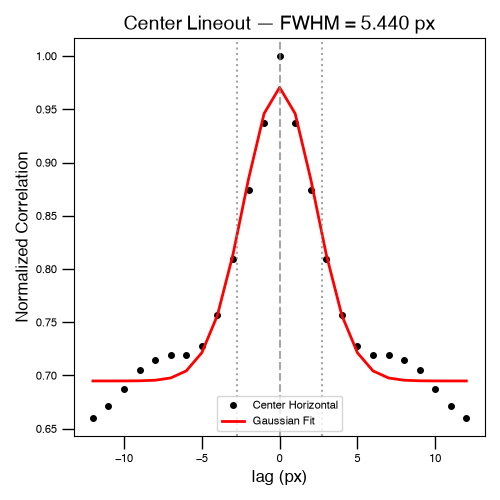

FWHM = 5.440 px  (sigma = 2.310 px, center x0 = 0.00 px)


In [8]:
# Fit center horizontal line of autocorrelation to a Gaussian; get FWHM in pixels
from scipy.optimize import curve_fit

ny, nx = acorr.shape
x_px = np.arange(nx, dtype=float)-12
y_line = acorr[ny // 2, :]

def gaussian(x, A, x0, sigma, offset=0.0):
    return A * np.exp(-((x - x0) ** 2) / (2 * sigma**2)) + offset

p0 = [1.0, 0, 10.0, 0.5]
bounds = (
    [0.0, - 5, 0.1, 0.0],   # A_min, x0_min, sigma_min, offset_min
    [2.0, 5, 10.0, 1.0],  # A_max, x0_max, sigma_max, offset_max
)
popt, pcov = curve_fit(gaussian, x_px, y_line, p0=p0, bounds=bounds)
A, x0, sigma, offset = popt

# FWHM = 2 * sqrt(2*ln(2)) * sigma
FWHM_px = 2 * np.sqrt(2 * np.log(2)) * sigma

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(x_px, y_line, "k.", ms=8, label="Center Horizontal")
ax.plot(x_px, gaussian(x_px, *popt), "r-", lw=2, label="Gaussian Fit")
ax.axvline(x0, color="gray", ls="--", alpha=0.7)
ax.axvline(x0 - FWHM_px / 2, color="gray", ls=":", alpha=0.7)
ax.axvline(x0 + FWHM_px / 2, color="gray", ls=":", alpha=0.7)

ax.tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font-4)
ax.tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=legend_ax_font-4)

ax.set_xlabel("lag (px)",fontsize=ax_label_font-4)
ax.set_ylabel("Normalized Correlation",fontsize=ax_label_font-4)
ax.legend(fontsize=legend_ax_font-4,loc="lower center")
ax.set_title(f"Center Lineout — FWHM = {FWHM_px:.3f} px",fontsize=ax_title_font-4)
plt.tight_layout()
plt.show()

print(f"FWHM = {FWHM_px:.3f} px  (sigma = {sigma:.3f} px, center x0 = {x0:.2f} px)")

#fig.savefig(figure_path / "gaussian_fit.pdf",format="pdf",dpi=300,bbox_inches="tight",metadata={'Creator': ''})


Saved FWHM grid to /Users/eriklamb/data/PETRA/PETRA_P10_November2023/Beamtime_11017686/raw/NPS_01_00219/e4m/speckle_fwhm_scan219.npz
FWHM (px): min=3.745, max=10.483, mean=6.213


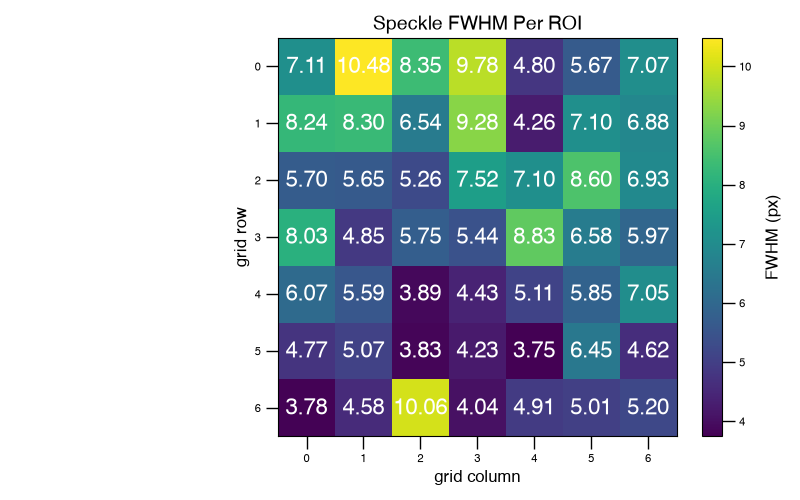

In [9]:
# Autocorrelation + Gaussian FWHM for each ROI in the 5×5 grid
from scipy.optimize import curve_fit


def gaussian(x, A, x0, sigma, offset=0.0):
    return A * np.exp(-((x - x0) ** 2) / (2 * sigma**2)) + offset


def speckle_acorr(patch):
    img = np.asarray(patch, dtype=float) + 1e-5
    F = np.fft.fft2(img)
    power = np.abs(F) ** 2
    acorr = np.fft.ifft2(power).real
    acorr = np.fft.fftshift(acorr)
    peak = acorr.max()
    return acorr / peak if peak > 0 else acorr


def fit_acorr_fwhm(acorr):
    ny, nx = acorr.shape
    x_px = np.arange(nx, dtype=float)
    y_line = acorr[ny // 2, :]
    p0 = [1.0, nx / 2.0, 2.0, 0.0]
    bounds = (
        [0.0, nx / 2 - 5, 0.1, 0.0],
        [2.0, nx / 2 + 5, 10.0, 1.0],
    )
    popt, _ = curve_fit(gaussian, x_px, y_line, p0=p0, bounds=bounds)
    sigma = popt[2]
    fwhm = 2 * np.sqrt(2 * np.log(2)) * sigma
    return fwhm, popt


fwhm_grid = np.full((n_grid, n_grid), np.nan)
fit_grid = np.full((n_grid, n_grid, 4), np.nan)

for ii in range(n_grid):
    for jj in range(n_grid):
        patch = extract_roi(raw_image[roi[0]:roi[1],roi[2]:roi[3]], ii, jj)
        ac = speckle_acorr(patch)
        try:
            fwhm, popt = fit_acorr_fwhm(ac)
            fwhm_grid[ii, jj] = fwhm
            fit_grid[ii, jj] = popt
        except RuntimeError as e:
            print(f"ROI ({ii}, {jj}) fit failed: {e}")

# Persist FWHM map (and ROI geometry / fit params) alongside the scan data
fwhm_out = work_path / f"speckle_fwhm_scan{Scan}.npz"
np.savez(
    fwhm_out,
    fwhm_px=fwhm_grid,
    roi_bounds=roi_bounds,
    fit_params=fit_grid,
    roi_size=roi_size,
    spacing=spacing,
)
print(f"Saved FWHM grid to {fwhm_out}")
print(f"FWHM (px): min={np.nanmin(fwhm_grid):.3f}, max={np.nanmax(fwhm_grid):.3f}, mean={np.nanmean(fwhm_grid):.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(fwhm_grid, origin="upper", cmap="viridis")
ax.set_xticks(range(n_grid))
ax.set_yticks(range(n_grid))

ax.tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font-4)
ax.tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=legend_ax_font-4)

ax.set_xlabel("grid column",fontsize=ax_label_font-4)
ax.set_ylabel("grid row",fontsize=ax_label_font-4)
for ii in range(n_grid):
    for jj in range(n_grid):
        if np.isfinite(fwhm_grid[ii, jj]):
            ax.text(jj, ii, f"{fwhm_grid[ii, jj]:.2f}", ha="center", va="center", color="w", fontsize=16)
# Add a color scale bar for the cropped image on the left side
cbar = plt.colorbar(im, ax=ax, fraction=0.05, pad=0.035, location="right")
cbar.set_label("FWHM (px)", fontsize=ax_label_font-4, labelpad=10)
# Make colorbar ticks longer, bolder
cbar.ax.tick_params(labelsize=legend_ax_font-4, length=major_tick_length, width=major_tick_width, which='both', direction='out', color='black')


ax.set_title(f"Speckle FWHM Per ROI",fontsize=ax_title_font-4)
plt.tight_layout()
plt.show()

#fig.savefig(figure_path / "speckle_fwhm.pdf",format="pdf",dpi=300,bbox_inches="tight",metadata={'Creator': ''})


In [10]:
sam_to_det = sam2det/1000 #meters
pixel_size = pix*1000 #microns
lam = lamb #Angstrom

print(f"sam_to_det: {sam_to_det}")
print(f"pixel_size: {pixel_size}")
print(f"lam: {lam}")



sam_to_det: 5.001
pixel_size: 75.00000356230885
lam: 0.8855986595153809


In [11]:
# Δℓ ≈ 1.22 * (f * λ) / D  =>  D = 1.22 * (sam_to_det * lam) / Δℓ
# Δℓ = pixel spread in physical units = FWHM_px * pixel_size
particle_size = []  

pixel_size_m = pixel_size * 1e-6          # µm -> m
lam_m = lam * 1e-10                       # Å -> m

for ii in range(n_grid):
    for jj in range(n_grid):
        if np.isfinite(fwhm_grid[ii, jj]):
            delta_ell_m = fwhm_grid[ii, jj] * pixel_size_m     # physical speckle size (m)

            D_m = 1.22 * sam_to_det * lam_m / delta_ell_m #Rayleigh size (m)

            particle_size.append(D_m*1e6) #μm

display(Math(r"\text{Speckle size: } %.4f \pm %.4f~pixels" % (np.mean(fwhm_grid), np.std(fwhm_grid)/np.sqrt(len(fwhm_grid)**2))))

display(Math(r"\text{Particle size: } %.4f \pm %.4f~\mu\mathrm{m}" % (np.mean(particle_size), np.std(particle_size)/np.sqrt(len(particle_size)))))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [12]:
sizes = [[219, '7x7', 6.2126,0.2505, 1.3287,0.0553],
        [334, '7x7', 6.5924,0.2872, 1.2792,0.0814],
        [552, '7x7', 6.5106,0.2357, 1.2287,0.0511],
        [579, '7x7', 5.2330,0.4126, 1.6643,0.1702],
        [709, '7x7', 5.0559,0.2140, 1.4780,0.0785],
        [779, '7x7', 6.5999,0.2993, 1.4547,0.2029],
        [796, '7x7', 6.9771,0.3576, 1.5636,0.2754],
        [868, '7x7', 5.9016,0.3253, 1.3154,0.092]]